## Binary Classification: Confusion Matrix, ROC Curve and AUC (Malaria Cell Images)

Based on the DigitalSreeni video *145 - Confusion matrix, ROC and AUC in machine learning* and the code in
[python_for_microscopists](https://github.com/bnsreenu/python_for_microscopists) (`144_145_binary_classification_ROC_AUC.py`) by Dr. Sreenivas Bhattiprolu.
Labels: **0 = Parasitized**, **1 = Uninfected**. The sigmoid output is the probability that an image is uninfected.

## Step 1 : Import

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Activation, Dropout, Flatten, Dense
from tensorflow.keras.utils import normalize

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc

## Step 2 : Load and Prepare the Data

In [2]:
import os
import numpy as np
from PIL import Image

# Find the dataset folder automatically
image_directory = None
for root, dirs, files in os.walk('C:/Users/samco/Downloads'):
    if 'Parasitized' in dirs and 'Uninfected' in dirs and '.ipynb_checkpoints' not in root:
        image_directory = root.replace('\\', '/') + '/'
        break

print("Found dataset at:", image_directory)

SIZE = 150
EPOCHS = 10

dataset = []
label = []

for image_name in os.listdir(image_directory + 'Parasitized/'):
    if image_name.split('.')[-1] == 'png':
        image = Image.open(image_directory + 'Parasitized/' + image_name).convert('RGB').resize((SIZE, SIZE))
        dataset.append(np.array(image))
        label.append(0)

for image_name in os.listdir(image_directory + 'Uninfected/'):
    if image_name.split('.')[-1] == 'png':
        image = Image.open(image_directory + 'Uninfected/' + image_name).convert('RGB').resize((SIZE, SIZE))
        dataset.append(np.array(image))
        label.append(1)

dataset = np.array(dataset)
label = np.array(label)
print("Images:", dataset.shape, "Labels:", label.shape)

Found dataset at: C:/Users/samco/Downloads/cells image/cell_images/
Images: (27558, 150, 150, 3) Labels: (27558,)


In [3]:
import os
import numpy as np
from PIL import Image

# Find the dataset folder automatically
image_directory = None
for root, dirs, files in os.walk('C:/Users/samco/Downloads'):
    if 'Parasitized' in dirs and 'Uninfected' in dirs and '.ipynb_checkpoints' not in root:
        image_directory = root.replace('\\', '/') + '/'
        break

print("Found dataset at:", image_directory)

SIZE = 65
EPOCHS = 10

dataset = []
label = []

for image_name in os.listdir(image_directory + 'Parasitized/'):
    if image_name.split('.')[-1] == 'png':
        image = Image.open(image_directory + 'Parasitized/' + image_name).convert('RGB').resize((SIZE, SIZE))
        dataset.append(np.array(image))
        label.append(0)

for image_name in os.listdir(image_directory + 'Uninfected/'):
    if image_name.split('.')[-1] == 'png':
        image = Image.open(image_directory + 'Uninfected/' + image_name).convert('RGB').resize((SIZE, SIZE))
        dataset.append(np.array(image))
        label.append(1)

dataset = np.array(dataset)
label = np.array(label)
print("Images:", dataset.shape, "Labels:", label.shape)

Found dataset at: C:/Users/samco/Downloads/cells image/cell_images/
Images: (27558, 65, 65, 3) Labels: (27558,)


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Rescaling, Conv2D, MaxPooling2D, Activation, Dropout, Flatten, Dense

SIZE = dataset.shape[1]   # picks up the image size from the loaded data
EPOCHS = 10

# Split (no normalize step, so no big memory copy)
X_train, X_test, y_train, y_test = train_test_split(dataset, label, test_size=0.20, random_state=0)
print(X_train.shape, X_test.shape)

# Build the CNN (sigmoid output for binary classification)
model = Sequential()
model.add(Input(shape=(SIZE, SIZE, 3)))
model.add(Rescaling(1.0 / 255))   # scales pixels to 0-1 inside the model

model.add(Conv2D(32, (3, 3)))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(32, (3, 3), kernel_initializer='he_uniform'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), kernel_initializer='he_uniform'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten())
model.add(Dense(64))
model.add(Activation('relu'))
model.add(Dropout(0.5))
model.add(Dense(1))
model.add(Activation('sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='rmsprop', metrics=['accuracy'])

# Train
history = model.fit(X_train, y_train,
                    batch_size=64,
                    verbose=1,
                    epochs=EPOCHS,
                    validation_data=(X_test, y_test),
                    shuffle=False)

# Accuracy
_, acc = model.evaluate(X_test, y_test)
print("Accuracy =", acc * 100.0, "%")

(22046, 65, 65, 3) (5512, 65, 65, 3)
Epoch 1/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 37s 100ms/step - accuracy: 0.7279 - loss: 0.5101 - val_accuracy: 0.9459 - val_loss: 0.1782
Epoch 2/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 31s 90ms/step - accuracy: 0.9456 - loss: 0.1747 - val_accuracy: 0.9505 - val_loss: 0.1628
Epoch 3/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.9539 - loss: 0.1532 - val_accuracy: 0.9526 - val_loss: 0.1494
Epoch 4/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 30s 87ms/step - accuracy: 0.9562 - loss: 0.1427 - val_accuracy: 0.9512 - val_loss: 0.1619
Epoch 5/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 30s 87ms/step - accuracy: 0.9565 - loss: 0.1379 - val_accuracy: 0.9536 - val_loss: 0.1509
Epoch 6/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 30s 87ms/step - accuracy: 0.9589 - loss: 0.1332 - val_accuracy: 0.9546 - val_loss: 0.1459
Epoch 7/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 30s 87ms/step - accuracy: 0.9597 - loss: 0.1261 - val_accuracy: 0.9554 - val_loss: 0.1432
Epoch 8/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 31s 90ms/ste

## 3. Build the CNN model (sigmoid output for binary classification)

In [5]:
INPUT_SHAPE = (SIZE, SIZE, 3)

model = Sequential()
model.add(Conv2D(32, (3, 3), input_shape=INPUT_SHAPE))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(32, (3, 3), kernel_initializer='he_uniform'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), kernel_initializer='he_uniform'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten())
model.add(Dense(64))
model.add(Activation('relu'))
model.add(Dropout(0.5))
model.add(Dense(1))
model.add(Activation('sigmoid'))   # sigmoid, not softmax, for binary classification

model.compile(loss='binary_crossentropy', optimizer='rmsprop', metrics=['accuracy'])
model.summary()

C:\Users\samco\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 63, 63, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 29, 29, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 176,225 (688.38 KB)

 Trainable params: 176,225 (688.38 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the model

In [6]:
history = model.fit(X_train, y_train,
                    batch_size=64,
                    verbose=1,
                    epochs=EPOCHS,
                    validation_data=(X_test, y_test),
                    shuffle=False)

model.save('malaria_model.keras')


Epoch 1/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 33s 94ms/step - accuracy: 0.5519 - loss: 1.4301 - val_accuracy: 0.7765 - val_loss: 0.5143
Epoch 2/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 29s 84ms/step - accuracy: 0.8729 - loss: 0.3364 - val_accuracy: 0.9267 - val_loss: 0.2447
Epoch 3/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 32s 93ms/step - accuracy: 0.9381 - loss: 0.2037 - val_accuracy: 0.9249 - val_loss: 0.2425
Epoch 4/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 34s 100ms/step - accuracy: 0.9409 - loss: 0.2000 - val_accuracy: 0.9507 - val_loss: 0.1656
Epoch 5/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 29s 85ms/step - accuracy: 0.9448 - loss: 0.1807 - val_accuracy: 0.9478 - val_loss: 0.1866
Epoch 6/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 30s 86ms/step - accuracy: 0.9491 - loss: 0.1670 - val_accuracy: 0.9514 - val_loss: 0.1632
Epoch 7/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 30s 87ms/step - accuracy: 0.9507 - loss: 0.1629 - val_accuracy: 0.9492 - val_loss: 0.1570
Epoch 8/10
345/345 ━━━━━━━━━━━━━━━━━━━━ 30s 86ms/step - accuracy: 0.9511 - loss: 0.1590 -

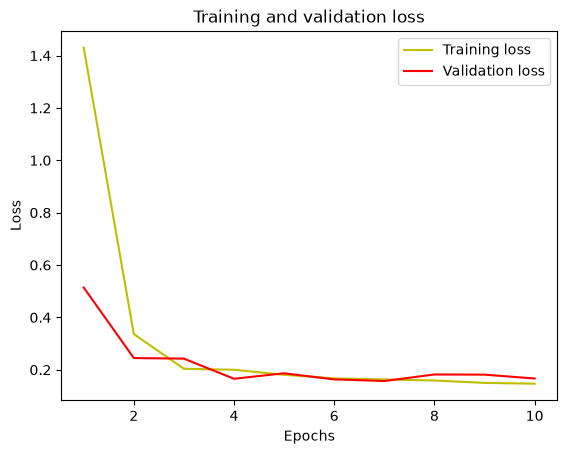

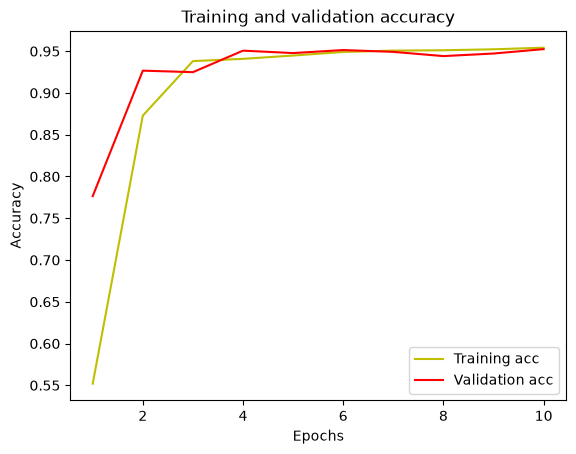

In [7]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend()
plt.show()

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
plt.plot(epochs, acc, 'y', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend()
plt.show()

## 5. Test on one image and check overall accuracy

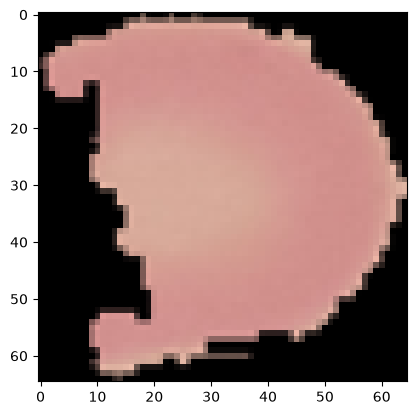

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step
The prediction for this image is:  [[0.7888363]]
The actual label for this image is:  1
173/173 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9525 - loss: 0.1666
Accuracy =  95.24673223495483 %


In [8]:
n = 24   # index of the test image
img = X_test[n]
plt.imshow(img)
plt.show()
input_img = np.expand_dims(img, axis=0)
print("The prediction for this image is: ", model.predict(input_img))
print("The actual label for this image is: ", y_test[n])

_, acc = model.evaluate(X_test, y_test)
print("Accuracy = ", acc * 100.0, "%")

## 6.ROC Curve

173/173 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step


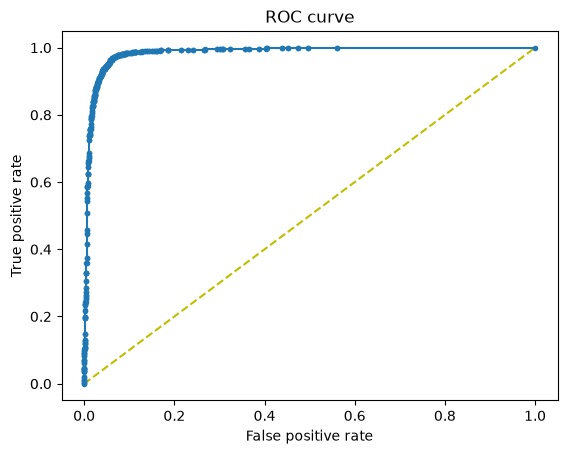

In [9]:
y_preds = model.predict(X_test).ravel()
fpr, tpr, thresholds = roc_curve(y_test, y_preds)

plt.figure(1)
plt.plot([0, 1], [0, 1], 'y--')
plt.plot(fpr, tpr, marker='.')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.show()

## 7. Ideal threshold and AUC

In [10]:
# Ideal threshold: where tpr-(1-fpr) is closest to zero (balance of TPR and TNR)
i = np.arange(len(tpr))
roc = pd.DataFrame({'tf': pd.Series(tpr - (1 - fpr), index=i),
                    'thresholds': pd.Series(thresholds, index=i)})
ideal_roc_thresh = roc.iloc[(roc.tf - 0).abs().argsort()[:1]]
ideal_threshold = float(ideal_roc_thresh['thresholds'].values[0])
print("Ideal threshold is: ", ideal_threshold)

# AUC: chance that the model can distinguish between the two classes
auc_value = auc(fpr, tpr)
print("Area under curve, AUC = ", auc_value)

Ideal threshold is:  0.7437012791633606
Area under curve, AUC =  0.985248778205775


## 8. Confusion matrix at different thresholds

In [11]:
for mythreshold in (0.5, ideal_threshold):
    y_pred = (y_preds >= mythreshold).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion matrix at threshold = %.3f" % mythreshold)
    print(cm, "\n")

Confusion matrix at threshold = 0.500
[[2512  191]
 [  71 2738]] 

Confusion matrix at threshold = 0.744
[[2564  139]
 [ 144 2665]] 



## Conclusion



A convolutional neural network with a sigmoid output was trained to classify 27,558 NIH malaria cell images as parasitized (0) or uninfected (1). Images were resized to 65×65 pixels and split 80/20 into training (22,046) and test (5,512) sets. The model was trained for 10 epochs.

- **Overall test accuracy:** The model reached **95.25%** accuracy on the test set. Training and validation accuracy were both about 95%, so there was no serious overfitting.
- **AUC:** The ROC curve gave an **AUC of 0.985**, close to the perfect value of 1.0 and far above the 0.5 of a random classifier. The model separates parasitized and uninfected cells very well.
- **Ideal threshold:** The threshold that best balances the true positive and true negative rates was **0.744**, compared with the default 0.5.
- **Confusion matrix at threshold 0.5:**

  | | Predicted parasitized | Predicted uninfected |
  |---|---|---|
  | **Actual parasitized** | 2512 | 191 |
  | **Actual uninfected** | 71 | 2738 |

  The model found 97.5% of uninfected cells but only 92.9% of parasitized cells. There were 191 parasitized cells wrongly labelled uninfected (false positives, since uninfected is the positive class) and 71 uninfected cells wrongly labelled parasitized (false negatives). In malaria screening the first error is the more serious one, because an infected cell is missed.

- **Confusion matrix at the ideal threshold (0.744):**

  | | Predicted parasitized | Predicted uninfected |
  |---|---|---|
  | **Actual parasitized** | 2564 | 139 |
  | **Actual uninfected** | 144 | 2665 |

  Both classes are now identified at about 94.9%. False positives fell from 191 to 139, while false negatives rose from 71 to 144. Overall accuracy dropped slightly, from 95.25% to 94.9%.

- **Effect of the threshold:** Raising the threshold makes the model predict "uninfected" less often. This reduces missed infections (false positives) but wrongly flags more healthy cells (false negatives). The threshold should be chosen according to which error matters more. Here, a higher threshold suits screening, where missing an infected cell is worse than a false alarm.

- **Overall:** A simple CNN trained for only 10 epochs on small images performs well. Training for more epochs, using larger images, or adding data augmentation could improve it further.

**Credit:** Code adapted from Dr. Sreenivas Bhattiprolu, *Python for Microscopists* (DigitalSreeni),https://github.com/bnsreenu/python_for_microscopists